# **TUGAS 7 Text Clustering**

**Kelompok 12**

**Anggota :**



*   Zahida Amanda Rahma (25031554033)
*   Nur Adlina Latifah (25031554068)



Link text = [berita_kompas_prepro.csv](https://drive.google.com/file/d/1lvGDsH-pTGAJo5-TUGafE7SfDVl8topk/view?usp=drive_link)

In [5]:
import warnings
warnings.filterwarnings("ignore")

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

import pandas as pd
df = pd.read_csv('berita_kompas_prepro.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['Prepro']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

#Unsupervised : KMeans

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [12]:
k = range(1,7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[99.15110650512156, 97.97644700231666, 96.58837692755017, 95.2656443712224, 93.99750501640098, 92.89192802829699]


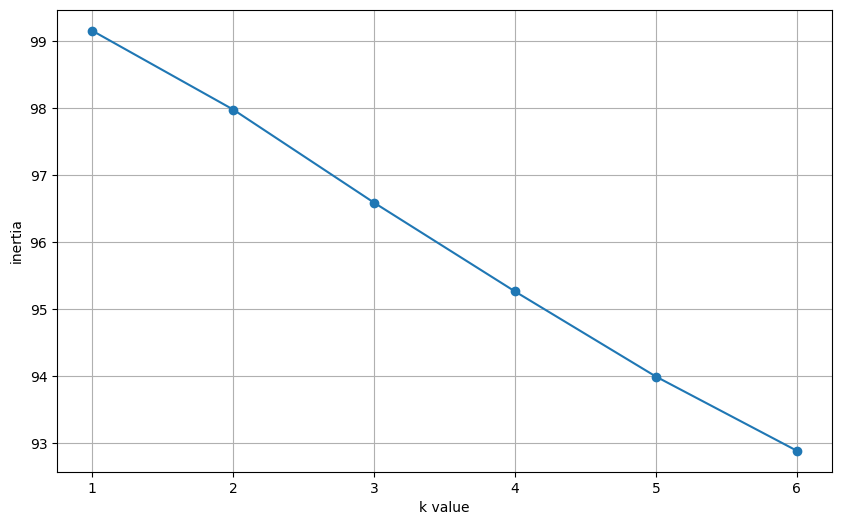

In [14]:
plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [15]:
c

3

In [17]:
n_clusters = 4
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [18]:
df['Kmeans_label'] = kM.labels_
df.head()

,Judul,Prepro,Kategori,Link,Tanggal,Kmeans_label
0,"Babak Baru ""Drama"" Bupati Gowa: Pemakzulan Dis...",babak drama bupati gowa makzul tuju ma kemenda...,Nasional,https://nasional.kompas.com/read/2026/10/04/11...,4 Oktober 2026,3
1,"Viral Video Keributan Remaja di Jalan Samas, P...",viral video ribut remaja jalan samas polres ba...,Yogyakarta,https://yogyakarta.kompas.com/read/2026/10/04/...,4 Oktober 2026,3
2,"Wanita di Sambas Ditemukan Tewas di Kamar, Did...",wanita sambas temu tewas kamar duga tusuk suami,Regional,https://regional.kompas.com/read/2026/10/04/10...,4 Oktober 2026,3
3,2 Pria Diduga Mesum di Toilet Stasiun Manggara...,2 pria duga mesum toilet stasiun manggarai tan...,Megapolitan,https://megapolitan.kompas.com/read/2026/10/04...,4 Oktober 2026,3
4,Kapolda NTT Irjen Rudi Darmoko Jabat Kalemdikl...,kapolda ntt irjen rudi darmoko jabat kalemdikl...,Nasional,https://nasional.kompas.com/read/2026/10/04/10...,4 Oktober 2026,1


**Silhouette Score**

In [19]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.0038793784082415544)

**Word Cloud**

Kmeans for cluster 0


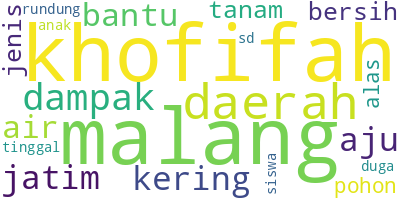

In [20]:
c = 0
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


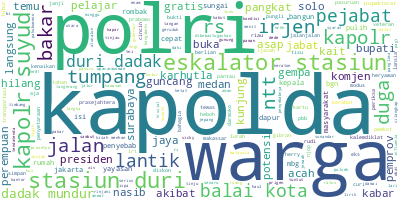

In [21]:
c = 1
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


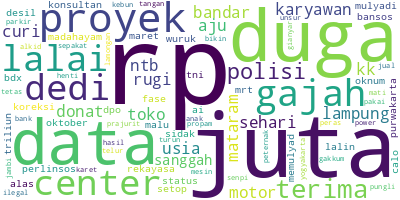

In [22]:
c = 2
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


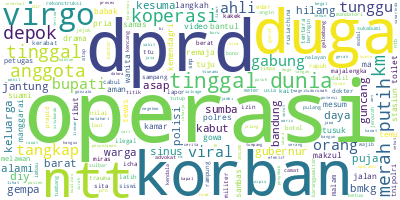

In [24]:
c = 3
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

#Unsupervised : Hierarchical

In [25]:
from scipy.cluster.hierarchy import dendrogram, linkage

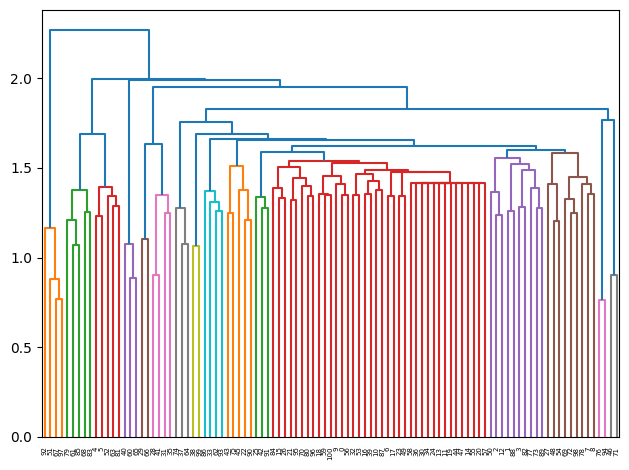

In [26]:
linkage_data = linkage(df_FE, method = 'ward', metric = 'euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = n_clusters, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [28]:
df.head()

,Judul,Prepro,Kategori,Link,Tanggal,Kmeans_label,Ward_label
0,"Babak Baru ""Drama"" Bupati Gowa: Pemakzulan Dis...",babak drama bupati gowa makzul tuju ma kemenda...,Nasional,https://nasional.kompas.com/read/2026/10/04/11...,4 Oktober 2026,3,0
1,"Viral Video Keributan Remaja di Jalan Samas, P...",viral video ribut remaja jalan samas polres ba...,Yogyakarta,https://yogyakarta.kompas.com/read/2026/10/04/...,4 Oktober 2026,3,0
2,"Wanita di Sambas Ditemukan Tewas di Kamar, Did...",wanita sambas temu tewas kamar duga tusuk suami,Regional,https://regional.kompas.com/read/2026/10/04/10...,4 Oktober 2026,3,0
3,2 Pria Diduga Mesum di Toilet Stasiun Manggara...,2 pria duga mesum toilet stasiun manggarai tan...,Megapolitan,https://megapolitan.kompas.com/read/2026/10/04...,4 Oktober 2026,3,0
4,Kapolda NTT Irjen Rudi Darmoko Jabat Kalemdikl...,kapolda ntt irjen rudi darmoko jabat kalemdikl...,Nasional,https://nasional.kompas.com/read/2026/10/04/10...,4 Oktober 2026,1,2


**Silhouette Score**

In [29]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.02646327907301995)

**Word Cloud**

Hierarchical for cluster 0


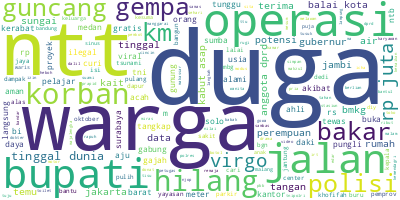

In [30]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

#Supervised: Sentiment Analysis

In [31]:
import pandas as pd
from wordcloud import WordCloud

df = pd.read_csv('berita_kompas_prepro.csv')
df = df.dropna().reset_index().drop(columns=['index'])

df_pre = df['Prepro']

#Word Cloud Sentiment Positive

Kategori: Nasional


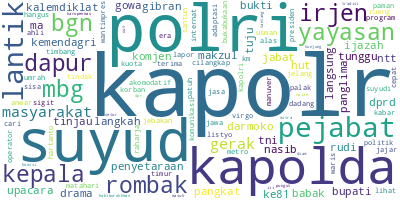

In [34]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

c = 'Nasional'
print('Kategori: ' + str(c))

df_c = df[df['Kategori'] == c]

long_string = ','.join(list(df_c['Prepro'].values))

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

#Word Cloud Sentiment Negative

Kategori: Regional


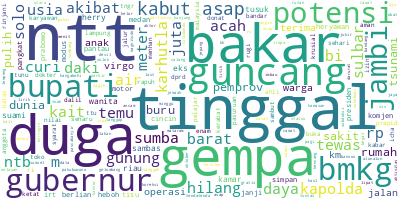

In [36]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

c = 'Regional'
print('Kategori: ' + str(c))

df_c = df[df['Kategori'] == c]

long_string = ','.join(list(df_c['Prepro'].values))

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

#Mengubah Teks Menjadi Matriks TF-IDF

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)

vecs

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 894 stored elements and shape (101, 631)>

#Classification

In [39]:
X = vecs
y = df['Kategori']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

#Random Forest Classifier

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 0  0  0  0  1  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  3  0  1  0  0]
 [ 0  0  0  0  6  0  0]
 [ 0  0  0  0 12  0  0]
 [ 0  0  0  0  5  0  0]
 [ 0  0  0  0  1  0  1]]
              precision    recall  f1-score   support

     Bandung       0.00      0.00      0.00         1
    Makassar       0.00      0.00      0.00         1
 Megapolitan       1.00      0.75      0.86         4
    Nasional       0.00      0.00      0.00         6
    Regional       0.44      1.00      0.62        12
    Surabaya       0.00      0.00      0.00         5
  Yogyakarta       1.00      0.50      0.67         2

    accuracy                           0.52        31
   macro avg       0.35      0.32      0.31        31
weighted avg       0.37      0.52      0.39        31



#Testing Sentiment

In [41]:
testing = "berita ini sangat bagus dan memberikan informasi bermanfaat"

testing = vectorizer.transform([testing])

testing = model.predict(testing)

print(testing)

['Regional']
